# Part 4A: Risk metrics for NVDA vs NVDL

**Question.** For NVDA and NVDL compute the standard deviation, 95% Value at Risk (VaR) and 95% Conditional VaR (CVaR) of daily returns (not annualized). Do the numbers corroborate that leverage increases risk?

**Data.** Daily total returns, 2024-02-01 to 2024-08-30 (147 trading days), file provided with the class project.

**Method.** Historical (empirical) approach. VaR(95%) is the 5th percentile of the daily return distribution. CVaR(95%) is the average of the returns at or below that percentile. Both are shown as returns (negative) and as loss magnitudes (positive).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = "{:,.4f}".format
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def find_root():
    """Walk up from the notebook folder until a folder containing data/raw is found."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "data" / "raw").is_dir():
            return base
    return Path.cwd()

def find_data(root):
    for folder in [root / "data" / "raw", root]:
        for p in folder.glob("*.xlsx"):
            n = p.name.lower()
            if "part" in n and "4" in n and "innov" in n:
                return p
    ws = Path("/mnt/user-data/uploads/class_project_data_part_4_-_product_innovation.xlsx")
    if ws.exists():
        return ws
    raise FileNotFoundError("Part 4 data file not found under data/raw")

ROOT = find_root()
OUT = ROOT / "output" / "part4"
OUT.mkdir(parents=True, exist_ok=True)

# Raw sheet: 5 header rows, then newest-first daily total returns in decimals (0.01 = 1%).
raw = pd.read_excel(find_data(ROOT), header=None, skiprows=5, names=["date", "NVDA", "NVDL"])
raw["date"] = pd.to_datetime(raw["date"])
df = raw.sort_values("date").set_index("date")     # ascending order is required before compounding
assert df.isna().sum().sum() == 0
print(f"{len(df)} trading days, {df.index.min().date()} to {df.index.max().date()}")

147 trading days, 2024-02-01 to 2024-08-30


In [2]:
def risk_table(r, alpha=0.05):
    var = np.percentile(r, alpha * 100)
    cvar = r[r <= var].mean()
    return pd.Series({
        "Std. dev. (daily)": r.std(ddof=1),
        "95% VaR (return)": var,
        "95% CVaR (return)": cvar,
        "95% VaR (loss)": -var,
        "95% CVaR (loss)": -cvar,
    })

tbl = pd.DataFrame({c: risk_table(df[c]) for c in ["NVDA", "NVDL"]})
tbl["NVDL / NVDA"] = tbl["NVDL"] / tbl["NVDA"]
tbl.to_csv(OUT / "4A_risk_metrics.csv")
tbl

,NVDA,NVDL,NVDL / NVDA
Std. dev. (daily),0.0375,0.0748,1.9967
95% VaR (return),-0.0612,-0.1203,1.9652
95% CVaR (return),-0.0707,-0.1416,2.0024
95% VaR (loss),0.0612,0.1203,1.9652
95% CVaR (loss),0.0707,0.1416,2.0024


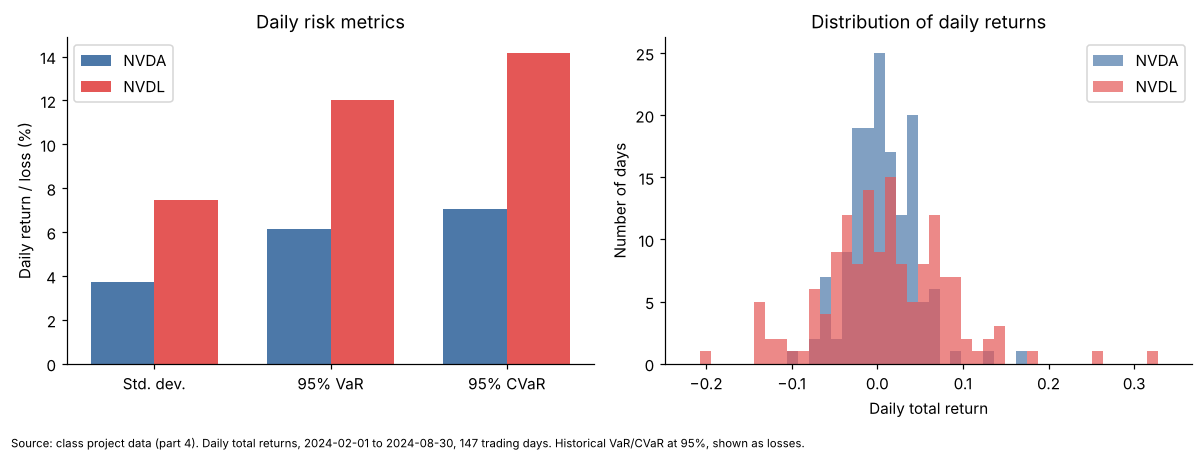

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

metrics = ["Std. dev. (daily)", "95% VaR (loss)", "95% CVaR (loss)"]
x = np.arange(len(metrics)); w = 0.36
ax[0].bar(x - w/2, tbl.loc[metrics, "NVDA"] * 100, w, label="NVDA", color="#4C78A8")
ax[0].bar(x + w/2, tbl.loc[metrics, "NVDL"] * 100, w, label="NVDL", color="#E45756")
ax[0].set_xticks(x); ax[0].set_xticklabels(["Std. dev.", "95% VaR", "95% CVaR"])
ax[0].set_ylabel("Daily return / loss (%)"); ax[0].set_title("Daily risk metrics"); ax[0].legend()

bins = np.linspace(-0.22, 0.34, 45)
ax[1].hist(df["NVDA"], bins=bins, alpha=0.7, label="NVDA", color="#4C78A8")
ax[1].hist(df["NVDL"], bins=bins, alpha=0.7, label="NVDL", color="#E45756")
ax[1].set_xlabel("Daily total return"); ax[1].set_ylabel("Number of days")
ax[1].set_title("Distribution of daily returns"); ax[1].legend()

fig.text(0.01, -0.03, "Source: class project data (part 4). Daily total returns, 2024-02-01 to 2024-08-30, 147 trading days. "
         "Historical VaR/CVaR at 95%, shown as losses.", fontsize=7.5, ha="left")
plt.tight_layout(); fig.savefig(OUT / "4A_risk_metrics.png", bbox_inches="tight"); plt.show()

## Comment

All three risk measures for NVDL are roughly twice those of NVDA (see the `NVDL / NVDA` column: standard deviation about 2.0x, VaR about 2.0x, CVaR about 2.0x). On a typical bad day (the worst 5% of days) NVDL lost at least about 12% while NVDA lost at least about 6%, and on those worst days the average loss was about 14% versus 7%.

This is what we expect from a fund designed to deliver twice the daily return: every daily move, up or down, is doubled, so the whole return distribution is stretched by a factor of about two. The metrics therefore corroborate that leverage increases risk, and the scaling is very close to the stated 2x leverage factor. Note that a larger risk is not matched by a proportionally better outcome, which is explored in 4C and 4D.